In [2]:
# Cancer Risk-Level Classification for Dreaded Disease Benefit Triage
# Client brief: A medical scheme wants to speed up the process of identifying 
# customers who may need cancer-related dreaded disease benefits. This notebook 
# conducts a basic analysis, selects features, trains a classification algorithm, 
# evaluates performance, and documents every step.
#
# Scope boundary: The supplied target is 'Level' (Low, Medium, High), not 
# confirmed cancer diagnosis or benefit eligibility. The model is therefore a 
# proof-of-concept triage classifier. It may support prioritisation for human 
# review, but it must not automatically approve, decline, price, diagnose, or 
# treat a member.

## 1. Dataset choice: quality and suitability

The dataset was selected because it directly supports a supervised multiclass classification task. It contains a labelled outcome (`Level`) and 23 potential predictors covering age, environmental exposure, lifestyle, medical history and symptoms. The three classes can serve as a proof-of-concept priority scale for routing cases for review.

**Quality strengths**

- 1,000 records and 25 columns provide enough observations for a basic academic classification exercise.
- The supplied file has no missing values and no exact duplicate rows.
- Variables are already numeric, while `Level` is a clearly defined three-class target.
- The class distribution is reasonably spread across Low, Medium and High, allowing all classes to be trained and evaluated.

**Material limitations**

- Excluding the identifier and target, the data contains only 152 unique predictor profiles; many IDs repeat the same measurements.
- The source, sampling design, coding scales and clinical validation are not documented in the supplied file.
- `Level` is not the same as confirmed cancer, a lodged claim, policy eligibility, benefit amount, clinical urgency or claim outcome.

For these reasons, the dataset is suitable for demonstrating the requested workflow, but not for operational benefit decisions without validated scheme claims, clinical and policy data.

## 2. Algorithm choice

A **Random Forest classifier** is selected as the primary algorithm.

1. The objective is multiclass classification of Low, Medium and High levels.
2. The predictors are numeric scores and likely contain non-linear relationships and interactions between exposures, behaviours and symptoms.
3. Random Forest can model these patterns without assuming a straight-line relationship or normal predictor distributions.
4. It is comparatively robust to outliers and correlated predictors, and it provides feature-importance values for explaining which variables influence the fitted model.
5. Class weighting can reduce bias toward the most common class.
6. Prediction is fast after training, which fits a triage workflow where cases need to be prioritised quickly.

A standardised **multinomial logistic regression** is retained as a transparent benchmark. If Random Forest does not materially outperform the benchmark, the simpler model may be preferable. Algorithm performance does not remove the need for human verification, policy checks and clinical evidence.

## 3. Analysis plan

| Stage | Succinct plan | Output / success check |
|---|---|---|
| EDA and cleaning | Load with a portable path; strip column names; inspect shape, types, missing values, duplicates, ranges, target balance and class-level patterns. | Clean modelling table and documented quality issues. |
| Leakage control | Remove `Patient Id`; group identical predictor profiles; keep each profile entirely in train or test data. | Zero shared profiles across partitions. |
| Feature selection | Fit selection on training data only; use Random Forest importance with a median threshold; review selected variables. | Smaller predictor set without using test information. |
| Train model | Train benchmark logistic regression and baseline Random Forest; use `class_weight='balanced'` and fixed seed. | Reproducible fitted classifiers. |
| Evaluate | Compare accuracy, balanced accuracy, macro-F1, class precision/recall/F1 and confusion matrices. Prioritise macro-F1 and High-class recall. | Evidence of overall and class-specific effectiveness. |
| Retrain if needed | Increase trees and set leaf size/max-features to improve stability and reduce overfitting; compare against baseline. | Keep refined model only if performance is maintained or improved. |
| Report | Summarise data quality, visual patterns, selection, training, metrics, limitations and operational safeguards. | Client-readable report linked to notebook evidence. |

## 4. Imports and reproducibility controls

In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
CLASS_ORDER = ['Low', 'Medium', 'High']
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

## 5. Load the dataset

The notebook searches the current folder and parent folders for `cancer_patient_data.csv`. The lecturer can therefore clone or download the GitHub repository and run the notebook without changing a Windows-specific path.

In [4]:
from pathlib import Path

# Portable data loading for GitHub/Jupyter/local PCs
# The notebook first searches for the CSV. If it is not found and the notebook
# is running in Google Colab, it offers a file-upload dialog.
def load_cancer_data(filename='cancer_patient_data.csv'):
    search_roots = [Path.cwd(), Path.home(), Path('/content'), Path('/mnt/data')]
    candidates = []
    for root in search_roots:
        if root.exists():
            candidates.append(root / filename)
            try:
                candidates.extend(root.glob(f'**/{filename}'))
            except (PermissionError, OSError):
                pass

    seen = set()
    for path in candidates:
        path = Path(path)
        key = str(path.resolve()) if path.exists() else str(path)
        if key not in seen:
            seen.add(key)
            if path.is_file():
                print(f'Loaded dataset from: {path.resolve()}')
                return pd.read_csv(path)

    # Optional fallback for Google Colab
    try:
        from google.colab import files
        print(f'{filename} was not found automatically. Please upload the CSV now.')
        uploaded = files.upload()
        if filename in uploaded:
            from io import BytesIO
            return pd.read_csv(BytesIO(uploaded[filename]))
        if uploaded:
            uploaded_name = next(iter(uploaded))
            print(f'Using uploaded file: {uploaded_name}')
            return pd.read_csv(BytesIO(uploaded[uploaded_name]))
    except ImportError:
        pass

    raise FileNotFoundError(
        f"Could not find {filename}. For GitHub/Jupyter, place the CSV in the same folder "
        "as this notebook (or a parent/subfolder) and run this cell again. "
        f"Current working directory: {Path.cwd()}"
    )

df = load_cancer_data()
df.columns = df.columns.str.strip()
print('Shape:', df.shape)
df.head()

Loaded dataset from: C:\Users\nbgum\Downloads\cancer_patient_data.csv
Shape: (1000, 25)


,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,Smoking,Passive Smoker,Chest Pain,Coughing of Blood,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,33,1,2,4,5,4,3,2,2,4,3,2,2,4,3,4,2,2,3,1,2,3,4,Low
1,P10,17,1,3,1,5,3,4,2,2,2,2,4,2,3,1,3,7,8,6,2,1,7,2,Medium
2,P100,35,1,4,5,6,5,5,4,6,7,2,3,4,8,8,7,9,2,1,4,6,7,2,High
3,P1000,37,1,7,7,7,7,6,7,7,7,7,7,7,8,4,2,3,1,4,5,6,7,5,High
4,P101,46,1,6,8,7,7,7,6,7,7,8,7,7,9,3,2,4,1,4,2,4,2,3,High


## 6. Conduct exploratory data analysis and cleaning

In [5]:
quality = pd.DataFrame({
    'data_type': df.dtypes.astype(str),
    'missing_values': df.isna().sum(),
    'unique_values': df.nunique()
})
display(quality)
print('Total missing values:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Unique predictor profiles:', df.drop(columns=['Patient Id', 'Level']).drop_duplicates().shape[0])
print('Target counts:')
display(df['Level'].value_counts().reindex(CLASS_ORDER).to_frame('count'))
df.describe().T

,data_type,missing_values,unique_values
Patient Id,str,0,1000
Age,int64,0,40
Gender,int64,0,2
Air Pollution,int64,0,8
Alcohol use,int64,0,8
Dust Allergy,int64,0,8
OccuPational Hazards,int64,0,8
Genetic Risk,int64,0,7
chronic Lung Disease,int64,0,7
Balanced Diet,int64,0,7


Total missing values: 0
Exact duplicate rows: 0
Unique predictor profiles: 152
Target counts:


,count
Level,
Low,303
Medium,332
High,365


,count,mean,std,min,25%,50%,75%,max
Age,1000.0,37.174,12.005493,14.0,27.75,36.0,45.0,73.0
Gender,1000.0,1.402,0.490547,1.0,1.00,1.0,2.0,2.0
Air Pollution,1000.0,3.840,2.030400,1.0,2.00,3.0,6.0,8.0
Alcohol use,1000.0,4.563,2.620477,1.0,2.00,5.0,7.0,8.0
Dust Allergy,1000.0,5.165,1.980833,1.0,4.00,6.0,7.0,8.0
OccuPational Hazards,1000.0,4.840,2.107805,1.0,3.00,5.0,7.0,8.0
Genetic Risk,1000.0,4.580,2.126999,1.0,2.00,5.0,7.0,7.0
chronic Lung Disease,1000.0,4.380,1.848518,1.0,3.00,4.0,6.0,7.0
Balanced Diet,1000.0,4.491,2.135528,1.0,2.00,4.0,7.0,7.0
Obesity,1000.0,4.465,2.124921,1.0,3.00,4.0,7.0,7.0


### Cleaning decisions

- Column-name whitespace is removed.
- `Patient Id` is excluded from modelling because it is an identifier, not a valid clinical or claims predictor.
- No missing-value imputation is required.
- Exact rows are not removed because none exist.
- Repeated predictor profiles are not silently deleted because they are attached to different IDs. Instead, profile grouping is used in the holdout split to prevent direct leakage.
- Gender remains available during initial exploration but is not automatically treated as a basis for benefit decisions.

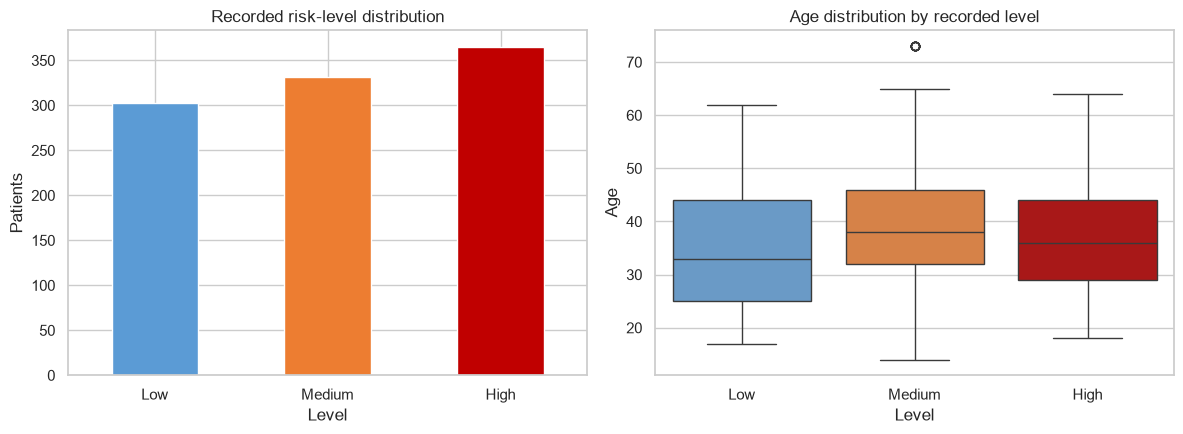

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df['Level'].value_counts().reindex(CLASS_ORDER).plot(
    kind='bar', ax=axes[0], color=['#5B9BD5', '#ED7D31', '#C00000'])
axes[0].set(title='Recorded risk-level distribution', xlabel='Level', ylabel='Patients')
axes[0].tick_params(axis='x', rotation=0)

sns.boxplot(data=df, x='Level', y='Age', hue='Level', order=CLASS_ORDER,
            palette=['#5B9BD5', '#ED7D31', '#C00000'], legend=False, ax=axes[1])
axes[1].set_title('Age distribution by recorded level')
plt.tight_layout(); plt.show()

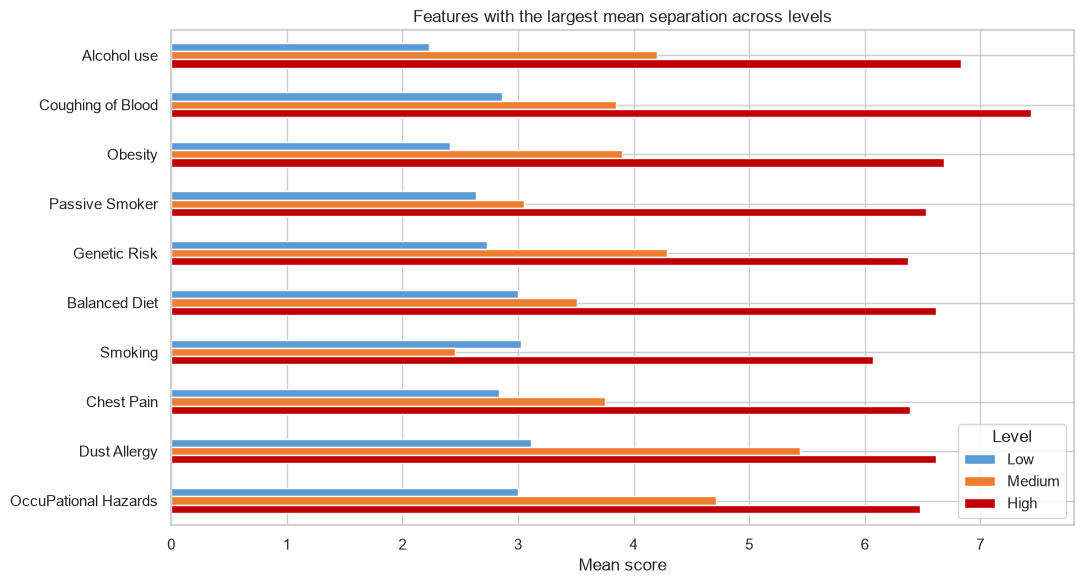

Level,Low,Medium,High
Alcohol use,2.23,4.20,6.83
Coughing of Blood,2.86,3.85,7.44
Obesity,2.41,3.90,6.68
Passive Smoker,2.63,3.05,6.53
Genetic Risk,2.73,4.29,6.38
Balanced Diet,3.00,3.51,6.62
Smoking,3.02,2.45,6.07
Chest Pain,2.83,3.75,6.39
Dust Allergy,3.11,5.44,6.62
OccuPational Hazards,3.00,4.72,6.48


In [7]:
predictor_columns = df.drop(columns=['Patient Id', 'Level']).columns
class_means = df.groupby('Level')[predictor_columns].mean().T
separation = (class_means.max(axis=1) - class_means.min(axis=1)).sort_values(ascending=False)
top10 = separation.head(10).index
class_means.loc[top10, CLASS_ORDER].plot(
    kind='barh', figsize=(11, 6), color=['#5B9BD5', '#ED7D31', '#C00000'])
plt.title('Features with the largest mean separation across levels')
plt.xlabel('Mean score'); plt.ylabel(''); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()
display(class_means.loc[top10, CLASS_ORDER].round(2))

### EDA interpretation

The target is not severely dominated by one class. Several exposure, lifestyle and symptom scores show visibly different class means, supporting a supervised classification approach. However, these are associations in the supplied labels and must not be interpreted as causal medical evidence.

## 7. Train/test split with leakage control

In [8]:
X = df.drop(columns=['Patient Id', 'Level'])
y = df['Level']
profile_groups = pd.util.hash_pandas_object(X, index=False).astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=profile_groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

shared = set(profile_groups.iloc[train_idx]) & set(profile_groups.iloc[test_idx])
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Shared predictor profiles:', len(shared))
print(); print('Test-class distribution:'); print(y_test.value_counts())

Training rows: 803
Testing rows: 197
Shared predictor profiles: 0

Test-class distribution:
Level
High      88
Medium    72
Low       37
Name: count, dtype: int64


## 8. Feature selection

Feature selection is performed **only on the training set** to prevent test-set information from influencing the model. A balanced Random Forest estimates feature importance, and `SelectFromModel` retains features at or above the median importance. This provides a reproducible embedded selection method suited to non-linear data. P-value elimination is not used because p-values belong naturally to parametric regression assumptions, whereas the selected primary model is tree-based.

In [9]:
selection_model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
selector = SelectFromModel(selection_model, threshold='median')
selector.fit(X_train, y_train)
selected_features = X_train.columns[selector.get_support()].tolist()

print('Selected feature count:', len(selected_features))
print(selected_features)
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

Selected feature count: 12
['Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Coughing of Blood', 'Fatigue', 'Shortness of Breath', 'Wheezing', 'Swallowing Difficulty']


## 9. Train benchmark, baseline and refined models

In [10]:
models = {
    'Logistic Regression benchmark': Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(max_iter=5000, class_weight='balanced',
                                     random_state=RANDOM_STATE))
    ]),
    'Random Forest baseline': RandomForestClassifier(
        n_estimators=100, class_weight='balanced', random_state=RANDOM_STATE,
        n_jobs=-1),
    'Random Forest refined': RandomForestClassifier(
        n_estimators=500, max_depth=None, min_samples_split=2,
        min_samples_leaf=2, max_features='sqrt', class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1)
}

results = {}
for name, model in models.items():
    model.fit(X_train_selected, y_train)
    pred = model.predict(X_test_selected)
    results[name] = {
        'model': model,
        'predictions': pred,
        'accuracy': accuracy_score(y_test, pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred),
        'macro_f1': f1_score(y_test, pred, average='macro')
    }

metrics = pd.DataFrame(results).T[['accuracy', 'balanced_accuracy', 'macro_f1']]
display(metrics.round(4))

,accuracy,balanced_accuracy,macro_f1
Logistic Regression benchmark,0.954315,0.918919,0.934238
Random Forest baseline,0.949239,0.962121,0.958275
Random Forest refined,0.949239,0.962121,0.958275


### Hyperparameter rationale

- `n_estimators=500` improves ensemble stability relative to the 100-tree baseline.
- `min_samples_leaf=2` prevents leaves based on a single training row and provides modest regularisation.
- `max_features='sqrt'` increases diversity between trees.
- `class_weight='balanced'` adjusts for class-frequency differences.
- `random_state=42` makes the split, selection and fitted models reproducible.

The refined model is retained only if it maintains or improves class-balanced performance. If it does not, the baseline result is reported transparently.

## 10. Interpret and evaluate the models

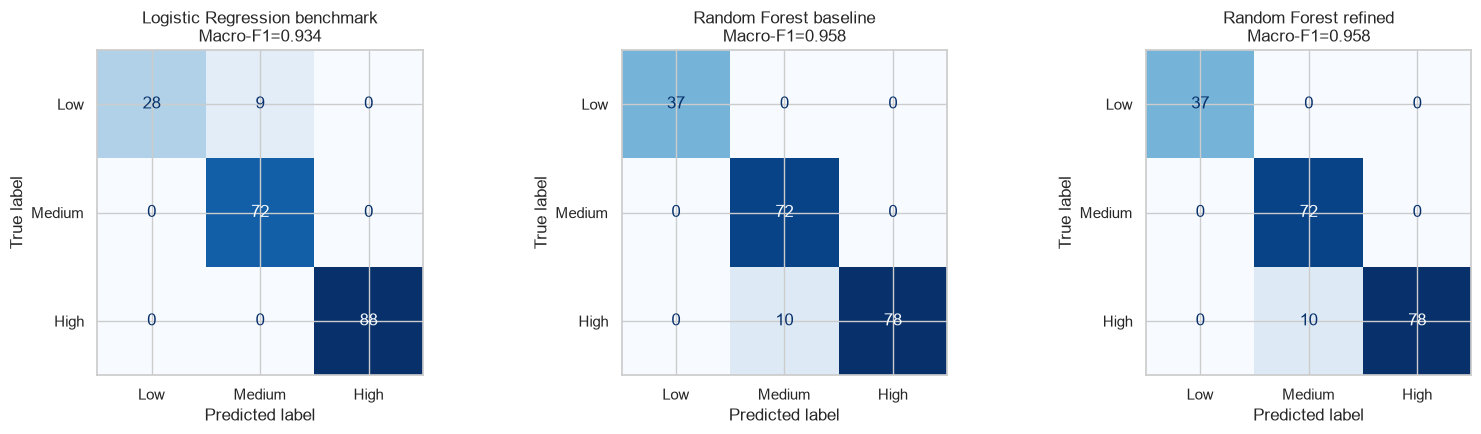


Logistic Regression benchmark
              precision    recall  f1-score   support

         Low       1.00      0.76      0.86        37
      Medium       0.89      1.00      0.94        72
        High       1.00      1.00      1.00        88

    accuracy                           0.95       197
   macro avg       0.96      0.92      0.93       197
weighted avg       0.96      0.95      0.95       197


Random Forest baseline
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        37
      Medium       0.88      1.00      0.94        72
        High       1.00      0.89      0.94        88

    accuracy                           0.95       197
   macro avg       0.96      0.96      0.96       197
weighted avg       0.96      0.95      0.95       197


Random Forest refined
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        37
      Medium       0.88      1.00      0.94        

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, result['predictions'], labels=CLASS_ORDER,
        display_labels=CLASS_ORDER, cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f"{name}\nMacro-F1={result['macro_f1']:.3f}")
plt.tight_layout(); plt.show()

for name, result in results.items():
    print()
    print(name)
    print(classification_report(y_test, result['predictions'],
                                labels=CLASS_ORDER, zero_division=0))

### Metric justification

- **Accuracy** gives the overall proportion of correct classifications.
- **Balanced accuracy** averages recall across classes, so a larger class cannot dominate the result.
- **Macro-F1** gives each class equal importance and balances precision with recall; it is the principal comparison metric.
- **High-class recall** is operationally important because missed High cases could delay review of customers who may need urgent assistance.
- **Confusion matrices** show the direction and number of errors, which a single score cannot reveal.

Good scores are not sufficient for deployment. A real benefits workflow would also require decision thresholds, probability calibration, external validation, policy-rule checks, clinical evidence and human review.

Selected model by macro-F1: Random Forest baseline
accuracy             0.9492
balanced_accuracy    0.9621
macro_f1             0.9583
Name: Random Forest baseline, dtype: object


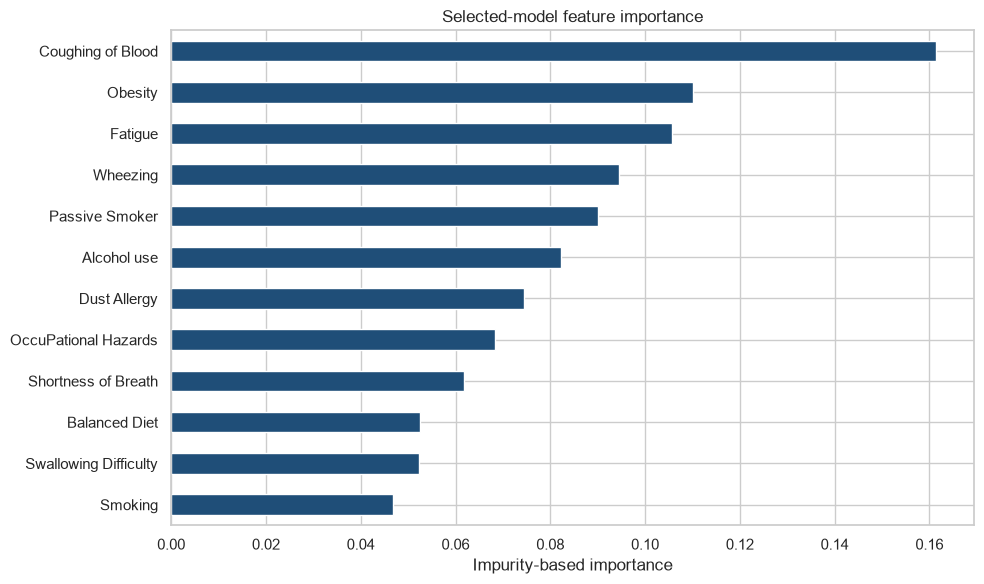

,importance
Coughing of Blood,0.1613
Obesity,0.1101
Fatigue,0.1056
Wheezing,0.0944
Passive Smoker,0.0901
Alcohol use,0.0822
Dust Allergy,0.0745
OccuPational Hazards,0.0684
Shortness of Breath,0.0617
Balanced Diet,0.0525


In [12]:
best_name = metrics['macro_f1'].idxmax()
best_model = results[best_name]['model']
print('Selected model by macro-F1:', best_name)
print(metrics.loc[best_name].round(4))

if hasattr(best_model, 'feature_importances_'):
    importance = pd.Series(best_model.feature_importances_, index=selected_features).sort_values(ascending=False)
    importance.sort_values().plot(kind='barh', figsize=(10, 6), color='#1F4E78')
    plt.title('Selected-model feature importance')
    plt.xlabel('Impurity-based importance'); plt.ylabel('')
    plt.tight_layout(); plt.show()
    display(importance.to_frame('importance').round(4))

## 11. Findings and recommendation

The selected model demonstrates that the supplied `Level` labels can be classified from the chosen variables under a group-aware holdout design. The model can be considered as a prototype for **routing** or **prioritising** cases for further assessment.

The model should not be described as determining cancer, confirming a claim, or applying a dreaded disease benefit. For a scheme-ready solution, replace or supplement this dataset with validated member, policy, claim, diagnosis, staging, treatment, documentation and adjudication-outcome fields. Define the business target as a verified benefit outcome, then externally validate and calibrate the model.

## 12. Limitations and responsible use

- Dataset provenance and clinical validation are not documented in the supplied file.
- Only 152 unique predictor profiles exist among 1,000 rows.
- The target does not represent confirmed cancer or policy eligibility.
- Feature importance is predictive, not causal.
- The analysis does not establish fairness, calibration, temporal stability or external validity.
- No automated adverse decision should be made from the model.

## 13. GitHub reproducibility

For the simplest GitHub/Jupyter setup, keep this notebook and `cancer_patient_data.csv` in the same repository folder. The loading cell also searches common local locations and subfolders, and in Google Colab it offers an upload dialog if the CSV is not found. Use Python 3.10+ and install:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn
```

Then restart the kernel and run all cells from top to bottom.